# Análisis: ¿cuándo un accidente se convierte en colapso del tráfico?
## Capa Silver → Gold · Accidentes de alto impacto en EE.UU. (2016–2023)

**Curso:** Big Data — Universidad Nacional de Juliaca (UNAJ) · 2026-2

**Docente:** Mg. Leibnihtz Abrahan Ayamamani Choque

**Integrantes:**
    - Charca Condori Yordi Brayan
    - Chura Puma Cristian Erik
    - Condori Quispe Kewin Erick
    - Inofuente Trujillo David Alex
    - Vargas Idme Vladimir Yordanov

Este es el **tercer y último notebook** del proyecto:

| # | Notebook | Capa | Qué hace |
|---|---|---|---|
| 1 | `01_exploration/01_eda_accidentes_eeuu.ipynb` | Bronze | Exploración: fuente, carga, perfil descriptivo y diccionario |
| 2 | `02_cleaning/02_silver_accidentes_eeuu.ipynb` | Bronze → Silver | Calidad en 6 dimensiones, columnas con ≤ 3 % de nulos, grupos comparables y variables derivadas |
| 3 | `03_analysis/03_analisis_accidentes_eeuu.ipynb` (**este**) | Silver → Gold | **Solo resultados y conclusiones**: la limpieza y la calidad ya se hicieron en el notebook 2 |

> **Para reproducir:** ejecutar antes el notebook 2 (crea la capa Silver). Luego **Kernel → Restart & Run All** en este notebook (menos de 1 minuto).

---
## 0. Pregunta, enfoque y reglas para no sobreinterpretar

> ### ¿Cuándo, dónde y bajo qué condiciones un accidente deja de ser un incidente aislado y se convierte en un colapso del tráfico?

**Colapso del tráfico** = accidente de **alto impacto** (severidad 3 o 4). La severidad mide el impacto en el tráfico (por ejemplo, el retraso que genera), **no** la gravedad de las lesiones.

| # | Sub-pregunta | Variables (todas con ≤ 3 % de nulos) |
|---|---|---|
| 1 | ¿En qué horas y días se concentran los accidentes de alto impacto? | `hora`, `franja_horaria`, `tipo_dia`, `dia_semana`, `Sunrise_Sunset` |
| 2 | ¿En qué estados y ciudades se concentran? | `State`, `City` |
| 3 | ¿Bajo qué condiciones climáticas aumenta la proporción de alto impacto? | `clima_grupo`, `visibilidad_grupo` (la precipitación se excluyó: 28,58 % de nulos) |
| 4 | ¿Qué elementos de la vía acompañan a los accidentes de alto impacto? | `Junction`, `Traffic_Signal`, `Crossing`, `Stop` |

### Los 4 niveles de análisis en Big Data

| Nivel | Pregunta que responde | Qué se hace en este notebook | Sección |
|---|---|---|---|
| **1. Descriptivo** | ¿Qué pasó? | Frecuencias por hora, día, lugar, clima y vía (análisis univariado) | 2 |
| **2. Diagnóstico** | ¿Con qué se asocia? ¿Por qué podría pasar? | Comparaciones dentro de grupos comparables (bivariado y multivariado) | 3 |
| **3. Predictivo** | ¿Qué podría pasar? | **No se incluye**: queda fuera del alcance de este trabajo | — |
| **4. Prescriptivo** | ¿Qué conviene hacer? | Recomendaciones con su nivel de solidez y lo que falta validar | 4 |

### Reglas para no dar por cierto un resultado

1. **Solo se compara dentro de un grupo comparable** (notebook 02, sección 6): **A = Source2 2016–2022** y **B = Source1 2021–2023**. Nunca se mezclan fuentes al hablar de severidad.
2. **Un patrón es "sólido" solo si aparece en los dos grupos** y en la misma dirección. Como A y B son fuentes y periodos distintos, que coincidan hace menos probable que el patrón sea un efecto de cómo registra una sola fuente.
3. **No se interpreta un subgrupo con menos de 500 accidentes**: con pocos casos, unos cuantos accidentes cambian mucho el porcentaje.
4. **Se habla de asociación, no de causa**: los datos muestran *qué ocurre junto*, no *qué lo provoca*.

### Cómo se compara: el índice de alto impacto

Como A tiene ~34 % de alto impacto y B ~3 % (criterios distintos), no se comparan sus porcentajes directamente. Se usa un **índice**:

$$\text{índice} = \frac{\% \text{ de alto impacto del subgrupo}}{\% \text{ de alto impacto promedio de su grupo}}$$

- **1,00** = igual al promedio de su grupo · **1,30** = 30 % más que el promedio · **0,70** = 30 % menos.
- Se considera una diferencia relevante si el índice es **≥ 1,10 o ≤ 0,90** (10 % o más de diferencia).

### Cómo influyen las 6 dimensiones de calidad en los resultados

Las reglas se evaluaron en el notebook 2 (secciones 5 y 6); aquí no se repiten, pero condicionan cómo se lee cada resultado:

| Dimensión | Resultado en el notebook 2 | Efecto en este análisis |
|---|---|---|
| Completitud | Todas las columnas usadas tienen ≤ 3 % de nulos (máximo 2,30 %) | Un registro sin dato solo sale del análisis que usa esa columna |
| Unicidad | 3 698 duplicados probables excluidos | Los conteos no están inflados |
| Validez | 100 % de severidades, fechas y coordenadas válidas | No hay valores imposibles en las variables usadas |
| Consistencia | La severidad cambia entre fuentes y entre años | Solo se compara dentro de los grupos A y B, con el índice |
| Exactitud (plausibilidad) | 97,23 % de registros con clima medido a ≤ 1 h | El análisis de clima usa solo `clima_confiable = True` |
| Oportunidad | Datos de feb-2016 a mar-2023; 2016 y 2023 incompletos | Solo se comparan años completos; los resultados describen el pasado |

---
## 1. Preparación

In [1]:
# Celda 1.1: localizar el proyecto, verificar dependencias y configurar los gráficos
import importlib.util
import json
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Localiza la raíz del repositorio por sus carpetas data/ y notebooks/
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto EDA (carpetas data/ y notebooks/).")


PROJECT_ROOT = find_project_root(Path.cwd())
SILVER_DIR = PROJECT_ROOT / "data" / "silver" / "us_accidents"
GOLD_DIR = PROJECT_ROOT / "data" / "gold" / "us_accidents"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "us_accidents"
for folder in (GOLD_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

REQUERIDAS = ["pandas", "numpy", "matplotlib", "seaborn", "scipy"]   # scipy: correlación de Spearman
faltantes = [lib for lib in REQUERIDAS if importlib.util.find_spec(lib) is None]
if faltantes:
    raise ModuleNotFoundError(
        "Faltan dependencias: " + ", ".join(faltantes) +
        ". Ejecute desde la raíz del proyecto: python -m pip install -r requirements.txt"
    )

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#c3c2b7", "axes.titlesize": 12,
})


def guardar_figura(fig, nombre: str) -> None:
    # Guarda cada gráfico en outputs/us_accidents/ para el informe
    fig.savefig(OUTPUT_DIR / f"{nombre}.png", dpi=120, bbox_inches="tight")


print(f"Proyecto : {PROJECT_ROOT}")
print(f"Python   : {sys.version.split()[0]} · pandas {pd.__version__}")

Proyecto : C:\Users\Erik\Documents\EDA-TF\EDA-bigdata
Python   : 3.12.10 · pandas 3.1.0


In [2]:
# Celda 1.2: constantes del análisis
GRUPO_A = "A: Source2 2016-2022"
GRUPO_B = "B: Source1 2021-2023"
GRUPOS = [GRUPO_A, GRUPO_B]
COLORES = {GRUPO_A: "#2a78d6", GRUPO_B: "#eb6834"}   # el color sigue al grupo en todo el notebook
COLOR_TODAS = "#6b6a65"                              # gris: todas las fuentes juntas (solo conteos)

MUESTRA_MINIMA = 500    # no se interpreta un subgrupo con menos accidentes
UMBRAL = 0.10           # diferencia mínima frente al promedio del grupo (10 %)

ORDEN_FRANJAS = ["06-10 Punta mañana", "10-15 Mediodía", "15-19 Punta tarde", "19-22 Noche", "22-06 Madrugada"]
HORAS_FRANJA = {"06-10 Punta mañana": 4, "10-15 Mediodía": 5, "15-19 Punta tarde": 4,
                "19-22 Noche": 3, "22-06 Madrugada": 8}
ORDEN_DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
ELEMENTOS_VIA = {"Junction": "Rampa o salida de autopista", "Traffic_Signal": "Semáforo",
                 "Crossing": "Cruce peatonal", "Stop": "Señal de pare"}

In [3]:
# Celda 1.3: cargar la capa Silver (la crea notebooks/02_cleaning/02_silver_accidentes_eeuu.ipynb)
RUTA_SILVER = SILVER_DIR / "us_accidents_silver.csv"
if not RUTA_SILVER.is_file():
    raise FileNotFoundError("No existe la capa Silver. Ejecute primero notebooks/02_cleaning/02_silver_accidentes_eeuu.ipynb")

silver = pd.read_csv(RUTA_SILVER, parse_dates=["Start_Time", "End_Time", "Weather_Timestamp"],
                     date_format="%Y-%m-%d %H:%M:%S")
registro = json.loads((SILVER_DIR / "registro_silver.json").read_text(encoding="utf-8"))
assert len(silver) == registro["filas_silver"], "Silver no coincide con su registro: vuelva a ejecutar el notebook 2"

print(f"Silver: {len(silver):,} accidentes × {silver.shape[1]} columnas")
print(f"Linaje: {registro['filas_bronze']:,} filas en Bronze → muestra fija de {registro['muestra']['filas']:,} "
      f"→ {registro['excluidas_duplicado_probable']:,} duplicados excluidos → {registro['filas_silver']:,} en Silver")
silver.head(3)

Silver: 537,290 accidentes × 31 columnas
Linaje: 7,728,394 filas en Bronze → muestra fija de 540,988 → 3,698 duplicados excluidos → 537,290 en Silver


,ID,Source,grupo_severidad,Severity,alto_impacto,Start_Time,End_Time,duracion_min,flag_duracion_irreal,anio,anio_completo,mes,hora,franja_horaria,dia_semana,tipo_dia,Sunrise_Sunset,Start_Lat,Start_Lng,City,State,Weather_Timestamp,clima_confiable,Weather_Condition,clima_grupo,Visibility(mi),visibilidad_grupo,Junction,Traffic_Signal,Crossing,Stop
0,A-104248,Source2,A: Source2 2016-2022,2,False,2016-04-25 17:18:11,2016-04-25 18:18:11,60.000000,False,2016,False,4,17,15-19 Punta tarde,Lunes,Laborable,Day,33.939304,-117.218231,Moreno Valley,CA,2016-04-25 16:58:00,True,Clear,Despejado,10.0,Normal (>=5 mi),False,False,False,False
1,A-199683,Source2,A: Source2 2016-2022,2,False,2017-01-10 09:40:16,2017-01-10 10:10:02,29.766667,False,2017,True,1,9,06-10 Punta mañana,Martes,Laborable,Day,42.549671,-71.847313,Fitchburg,MA,2017-01-10 09:52:00,True,Clear,Despejado,10.0,Normal (>=5 mi),False,False,False,False
2,A-140206,Source2,A: Source2 2016-2022,3,True,2016-09-02 17:27:56,2016-09-02 18:27:56,60.000000,False,2016,False,9,17,15-19 Punta tarde,Viernes,Laborable,Day,26.203491,-80.143852,Fort Lauderdale,FL,2016-09-02 17:53:00,True,Clear,Despejado,10.0,Normal (>=5 mi),False,False,False,False


---
## 2. Análisis descriptivo (nivel 1): ¿qué pasó?

En este nivel se describe **una variable a la vez** (análisis univariado): cuántos accidentes hay en cada hora, día, lugar, clima y tipo de vía. Los **conteos** pueden usar todas las fuentes; los **porcentajes de alto impacto** se muestran siempre por grupo comparable.

### 2.1 ¿A qué hora y qué día se registran los accidentes?

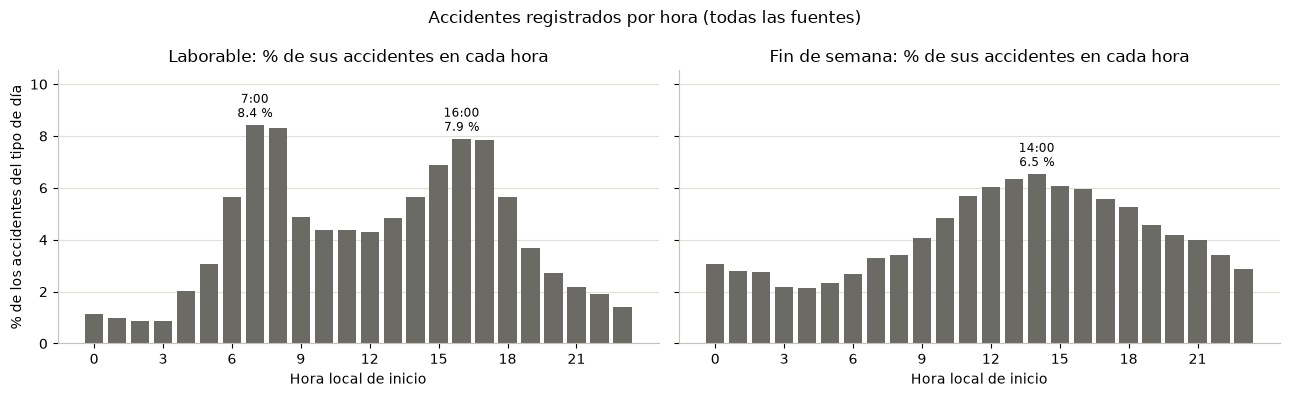

dia_semana,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
% de los accidentes,15.67,16.73,17.04,17.06,17.62,8.64,7.24


In [4]:
# Celda 2.1: reparto de los accidentes por hora en días laborables y fines de semana (todas las fuentes)
reparto_hora = pd.crosstab(silver["hora"], silver["tipo_dia"], normalize="columns").mul(100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, tipo in zip(axes, ["Laborable", "Fin de semana"]):
    serie = reparto_hora[tipo]
    ax.bar(serie.index, serie.values, color=COLOR_TODAS, width=0.8)
    picos = [serie[:12].idxmax(), serie[12:].idxmax()] if tipo == "Laborable" else [serie.idxmax()]
    for hora in picos:                       # se rotulan solo los picos
        ax.text(hora, serie[hora] + 0.15, f"{hora}:00\n{serie[hora]:.1f} %", ha="center", va="bottom", fontsize=8.5)
    ax.set_title(f"{tipo}: % de sus accidentes en cada hora")
    ax.set_xlabel("Hora local de inicio")
    ax.set_xticks(range(0, 24, 3))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% de los accidentes del tipo de día")
axes[0].set_ylim(0, reparto_hora.values.max() * 1.25)
fig.suptitle("Accidentes registrados por hora (todas las fuentes)")
plt.tight_layout()
guardar_figura(fig, "analisis_01_accidentes_por_hora")
plt.show()

por_dia = silver["dia_semana"].value_counts().reindex(ORDEN_DIAS)
display((por_dia / len(silver) * 100).round(2).to_frame("% de los accidentes").T)

**Interpretación:** en días laborables hay **dos picos**: la mañana (7:00, 8,4 % de los accidentes del día) y la tarde (16:00, 7,9 %), que coinciden con la entrada y salida del trabajo. El fin de semana tiene un **solo pico al mediodía** (14:00, 6,5 %). Cada día laborable concentra entre 15,7 % y 17,6 % de los accidentes; el sábado 8,6 % y el domingo 7,2 %.

Este patrón coincide con lo que reportan los autores del dataset (picos a las 8 y 17 h en días laborables y a las 13 h en fin de semana), con una hora de diferencia. Que **dos análisis independientes encuentren lo mismo** da más confianza en la variable `Start_Time`. Ojo: esto describe **cuántos** accidentes hay, no **cuáles** son de alto impacto.

### 2.2 ¿Dónde se registran más accidentes de alto impacto?

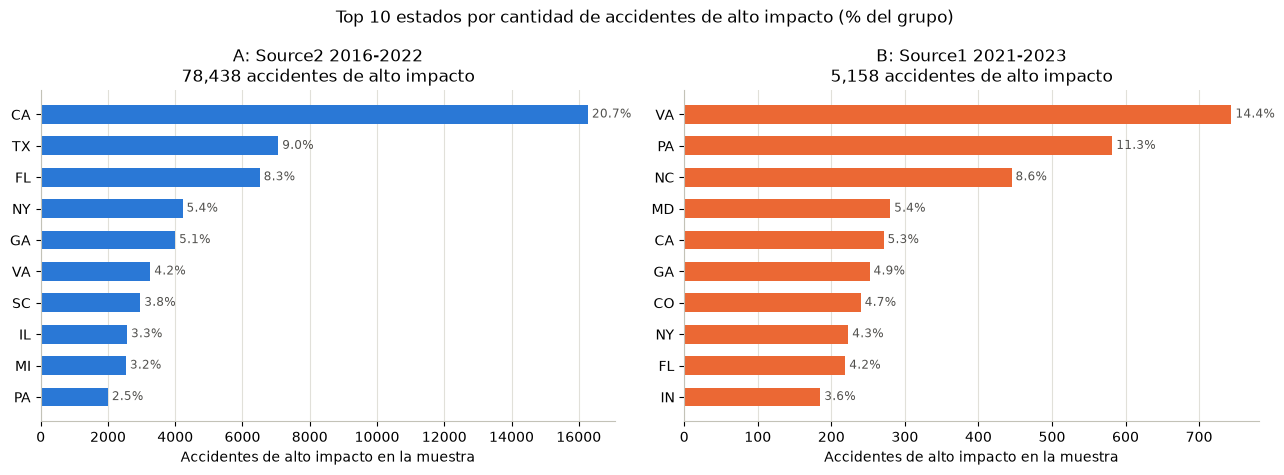

A: Source2 2016-2022: los 3 primeros estados reúnen 38.1% de sus casos de alto impacto
B: Source1 2021-2023: los 3 primeros estados reúnen 34.3% de sus casos de alto impacto


In [5]:
# Celda 2.2: los 10 estados con más accidentes de alto impacto, dentro de cada grupo
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
top_estados = {}
for ax, grupo in zip(axes, GRUPOS):
    datos = silver[(silver["grupo_severidad"] == grupo) & silver["alto_impacto"]]
    top = datos["State"].value_counts().head(10)
    top_estados[grupo] = top
    ax.barh(top.index, top.values, color=COLORES[grupo], height=0.6)
    for i, v in enumerate(top.values):
        ax.text(v, i, f" {v / len(datos):.1%}", va="center", fontsize=8.5, color="#52514e")
    ax.invert_yaxis()
    ax.set_title(f"{grupo}\n{len(datos):,} accidentes de alto impacto")
    ax.set_xlabel("Accidentes de alto impacto en la muestra")
    ax.grid(axis="y", visible=False)
fig.suptitle("Top 10 estados por cantidad de accidentes de alto impacto (% del grupo)")
plt.tight_layout()
guardar_figura(fig, "analisis_02_top_estados_alto_impacto")
plt.show()

for grupo, top in top_estados.items():
    total = silver[(silver["grupo_severidad"] == grupo) & silver["alto_impacto"]].shape[0]
    print(f"{grupo}: los 3 primeros estados reúnen {top.head(3).sum() / total:.1%} de sus casos de alto impacto")

**Interpretación:** en ambos grupos los casos se concentran en pocos estados (los 3 primeros reúnen **38,1 %** en A y **34,3 %** en B), pero **los estados no son los mismos**: en A lideran California, Texas y Florida; en B, Virginia, Pensilvania y Carolina del Norte. California es el primero en A (20,7 %) y apenas el quinto en B (5,3 %).

Esto muestra que **"dónde" depende de qué fuente se mire**: cada proveedor tiene distinta cobertura en cada estado. Antes de concluir sobre lugares hay que comparar proporciones dentro de cada grupo (sección 3.3).

### 2.3 ¿Con qué clima y cerca de qué elementos de la vía ocurren los accidentes?

In [6]:
# Celda 2.3: distribución del clima (solo clima confiable) y de los elementos de la vía, por grupo
en_grupos = silver[silver["grupo_severidad"].isin(GRUPOS)]
con_clima = en_grupos[en_grupos["clima_confiable"] & en_grupos["clima_grupo"].notna()]

frec_clima = pd.crosstab(con_clima["clima_grupo"], con_clima["grupo_severidad"], normalize="columns").mul(100)
frec_via = en_grupos.groupby("grupo_severidad")[list(ELEMENTOS_VIA)].mean().mul(100).T
frec_via.index = frec_via.index.map(ELEMENTOS_VIA)

print("% de accidentes según el clima (registros con clima confiable)")
display(frec_clima.sort_values(GRUPO_A, ascending=False).round(2))
print("% de accidentes con cada elemento de la vía a poca distancia")
display(frec_via.round(2))

% de accidentes según el clima (registros con clima confiable)


grupo_severidad,A: Source2 2016-2022,B: Source1 2021-2023
clima_grupo,,
Nublado,46.13,36.61
Despejado,41.36,49.52
Lluvia,7.07,6.30
Niebla o humo,2.54,2.68
Nieve o hielo,1.77,3.24
Tormenta,1.10,1.57
Otro,0.02,0.08


% de accidentes con cada elemento de la vía a poca distancia


grupo_severidad,A: Source2 2016-2022,B: Source1 2021-2023
Rampa o salida de autopista,5.06,6.70
Semáforo,22.21,7.46
Cruce peatonal,14.47,8.98
Señal de pare,3.23,2.64


**Interpretación:** la mayoría de los accidentes ocurre con cielo **nublado o despejado** (87 % en A y 86 % en B); la lluvia acompaña a entre 6 % y 7 %, y la nieve o hielo y las tormentas a menos del 4 %. Por eso las condiciones extremas tienen **pocos casos** y sus porcentajes son menos estables.

En la vía aparece una diferencia llamativa: el **22,2 %** de los accidentes de A ocurre cerca de un semáforo, frente a solo **7,5 %** en B. El paper del dataset ya advertía que una fuente reporta más accidentes cerca de intersecciones y la otra más cerca de rampas de autopista. Es decir, **las fuentes no cubren los mismos tipos de calles**, y eso hay que recordarlo al interpretar la sección 3.5.

---
## 3. Análisis diagnóstico (nivel 2): ¿con qué se asocia el alto impacto?

Ahora se relacionan **dos o más variables** (análisis bivariado y multivariado): ¿en qué horas, lugares, climas y vías es **más probable** que un accidente sea de alto impacto? Todo se calcula **dentro de cada grupo** y se resume con el índice (sección 0).

In [7]:
# Celda 3.0: funciones de apoyo para todo el diagnóstico
def tasa_por_categoria(datos, columna):
    # % de alto impacto de cada categoría, calculado POR SEPARADO en cada grupo comparable
    datos = datos[datos["grupo_severidad"].isin(GRUPOS)]
    tabla = (datos.groupby(["grupo_severidad", columna], observed=True)
                  .agg(accidentes=("ID", "size"), alto_impacto=("alto_impacto", "sum"))
                  .reset_index())
    tabla["pct_alto"] = tabla["alto_impacto"] / tabla["accidentes"] * 100
    promedio_grupo = datos.groupby("grupo_severidad")["alto_impacto"].mean() * 100
    tabla["indice"] = tabla["pct_alto"] / tabla["grupo_severidad"].map(promedio_grupo)
    return tabla


def clasificar(indice_a, indice_b):
    # Lectura prudente: un patrón es "sólido" solo si los DOS grupos coinciden
    alto, bajo = 1 + UMBRAL, 1 - UMBRAL
    if indice_a >= alto and indice_b >= alto:
        return "Sólido: más alto impacto"
    if indice_a <= bajo and indice_b <= bajo:
        return "Sólido: menos alto impacto"
    if (indice_a >= alto and indice_b <= bajo) or (indice_a <= bajo and indice_b >= alto):
        return "Contradictorio"
    return "No concluyente"


def comparar_grupos(datos, columna, variable):
    # Pone lado a lado los grupos A y B y clasifica cada categoría
    tabla = tasa_por_categoria(datos, columna)
    ancho = tabla.pivot(index=columna, columns="grupo_severidad", values=["accidentes", "pct_alto", "indice"])
    resumen = pd.DataFrame({
        "Variable": variable,
        "n A": ancho[("accidentes", GRUPO_A)].fillna(0).astype(int),
        "% alto A": ancho[("pct_alto", GRUPO_A)].round(2),
        "índice A": ancho[("indice", GRUPO_A)].round(2),
        "n B": ancho[("accidentes", GRUPO_B)].fillna(0).astype(int),
        "% alto B": ancho[("pct_alto", GRUPO_B)].round(2),
        "índice B": ancho[("indice", GRUPO_B)].round(2),
    })
    resumen["Lectura"] = [clasificar(a, b) for a, b in zip(resumen["índice A"], resumen["índice B"])]
    poca_muestra = (resumen["n A"] < MUESTRA_MINIMA) | (resumen["n B"] < MUESTRA_MINIMA)
    resumen.loc[poca_muestra, "Lectura"] = "Muestra insuficiente"
    return resumen.rename_axis("Categoría").reset_index()


def grafico_indices(tabla, titulo, nombre_archivo):
    # Barras horizontales del índice de A y B para cada categoría (línea en 1 = promedio del grupo)
    tabla = tabla[tabla["Lectura"] != "Muestra insuficiente"].reset_index(drop=True)
    y = np.arange(len(tabla))
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(tabla) + 1.8))
    for desplazamiento, grupo, col in [(-0.2, GRUPO_A, "índice A"), (0.2, GRUPO_B, "índice B")]:
        ax.barh(y + desplazamiento, tabla[col], height=0.38, color=COLORES[grupo], label=grupo,
                edgecolor="white", linewidth=2)
    ax.axvline(1, color="#52514e", linewidth=1)
    ax.set_yticks(y, [f"{c}\n({l})" for c, l in zip(tabla["Categoría"], tabla["Lectura"])], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel("Índice de alto impacto (1 = promedio de su grupo)")
    ax.set_title(titulo)
    ax.legend(frameon=False, loc="lower right")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    guardar_figura(fig, nombre_archivo)
    plt.show()

### 3.1 La trampa de mezclar fuentes

¿Qué pasaría si se calculara el % de alto impacto de cada año **sin controlar la fuente**?

,Todas las fuentes mezcladas,A: Source2 2016-2022,B: Source1 2021-2023,% registros de Source1
anio,,,,
2017,35.8,36.6,NaN,23.8
2018,35.6,35.9,NaN,18.6
2019,27.9,30.4,NaN,27.5
2020,18.4,30.5,NaN,59.8
2021,11.5,34.2,2.5,70.9
2022,6.8,34.1,2.6,86.4


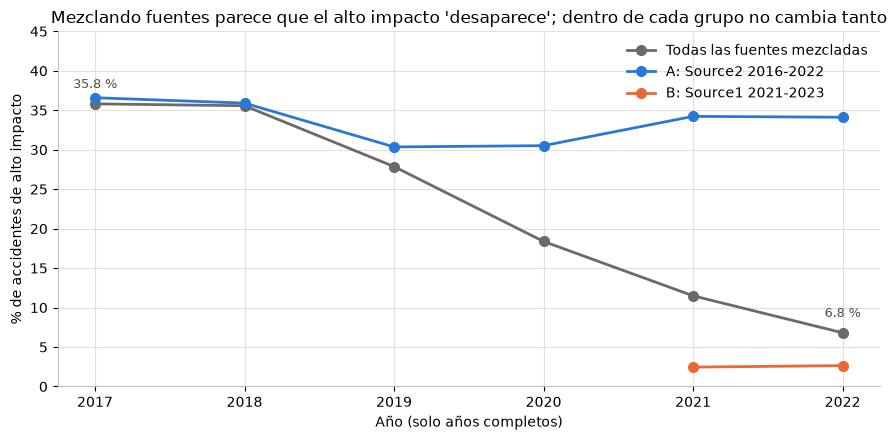

In [8]:
# Celda 3.1: % de alto impacto por año: todas las fuentes mezcladas frente a cada grupo (solo años completos)
completos = silver[silver["anio_completo"]]
mezcla = completos.groupby("anio")["alto_impacto"].mean().mul(100).rename("Todas las fuentes mezcladas")
por_grupo_anio = (completos[completos["grupo_severidad"].isin(GRUPOS)]
                  .groupby(["anio", "grupo_severidad"])["alto_impacto"].mean().mul(100).unstack())
peso_source1 = completos.groupby("anio")["Source"].apply(lambda s: (s == "Source1").mean() * 100)
display(pd.concat([mezcla, por_grupo_anio, peso_source1.rename("% registros de Source1")], axis=1).round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(mezcla.index, mezcla.values, marker="o", markersize=7, linewidth=2, color=COLOR_TODAS, label=mezcla.name)
for grupo in GRUPOS:
    serie = por_grupo_anio[grupo].dropna()
    ax.plot(serie.index, serie.values, marker="o", markersize=7, linewidth=2, color=COLORES[grupo], label=grupo)
ax.text(mezcla.index[0], mezcla.iloc[0] + 2, f"{mezcla.iloc[0]:.1f} %", ha="center", fontsize=9, color="#52514e")
ax.text(mezcla.index[-1], mezcla.iloc[-1] + 2, f"{mezcla.iloc[-1]:.1f} %", ha="center", fontsize=9, color="#52514e")
ax.set_ylim(0, 45)
ax.set_xlabel("Año (solo años completos)")
ax.set_ylabel("% de accidentes de alto impacto")
ax.set_title("Mezclando fuentes parece que el alto impacto 'desaparece'; dentro de cada grupo no cambia tanto")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
guardar_figura(fig, "analisis_03_trampa_mezclar_fuentes")
plt.show()

**Interpretación: por qué no se puede mezclar fuentes**

- Si se mezclan todas las fuentes, el alto impacto parece **caer de 35,8 % (2017) a 6,8 % (2022)**. Alguien podría concluir que "los accidentes ya no colapsan el tráfico".
- Pero dentro del grupo **A** el porcentaje se mantiene (36,6 % → 34,1 %) y dentro de **B** también (2,5 % → 2,6 %).
- La "caída" se explica porque **Source1 pasó de ser el 23,8 % de los registros (2017) al 86,4 % (2022)**, y Source1 usa hoy un criterio que casi nunca asigna alto impacto. Cambió **quién registra**, no necesariamente el tráfico.

Este es un ejemplo de la **paradoja de Simpson** vista en clase: un promedio global que mezcla grupos distintos puede contar una historia falsa. Es el hallazgo más importante para la **dimensión de consistencia**.

### 3.2 Sub-pregunta 1 — Tiempo: ¿a qué hora es más probable el alto impacto?

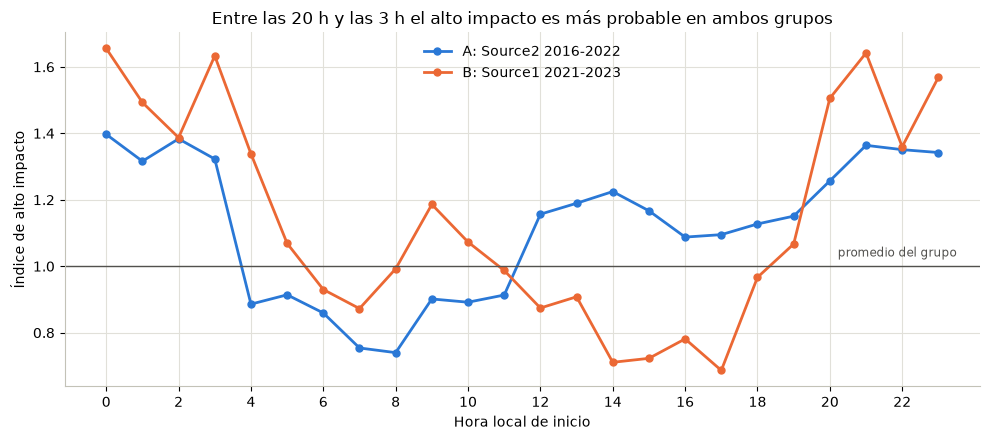

Horas con índice ≥ 1.10 en AMBOS grupos: [0, 1, 2, 3, 20, 21, 22, 23]


In [9]:
# Celda 3.2: índice de alto impacto por hora en cada grupo
por_hora = tasa_por_categoria(silver, "hora")

fig, ax = plt.subplots(figsize=(10, 4.5))
for grupo in GRUPOS:
    serie = por_hora[por_hora["grupo_severidad"] == grupo]
    ax.plot(serie["hora"], serie["indice"], marker="o", markersize=5, linewidth=2, color=COLORES[grupo], label=grupo)
ax.axhline(1, color="#52514e", linewidth=1)
ax.text(23.5, 1.02, "promedio del grupo", ha="right", va="bottom", fontsize=8.5, color="#52514e")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora local de inicio")
ax.set_ylabel("Índice de alto impacto")
ax.set_title("Entre las 20 h y las 3 h el alto impacto es más probable en ambos grupos")
ax.legend(frameon=False, loc="upper center")
plt.tight_layout()
guardar_figura(fig, "analisis_04_indice_por_hora")
plt.show()

indice_hora = por_hora.pivot(index="hora", columns="grupo_severidad", values="indice")
horas_solidas = indice_hora[(indice_hora[GRUPO_A] >= 1 + UMBRAL) & (indice_hora[GRUPO_B] >= 1 + UMBRAL)].index.tolist()
print(f"Horas con índice ≥ {1 + UMBRAL:.2f} en AMBOS grupos: {horas_solidas}")

In [10]:
# Celda 3.3: franja horaria, tipo de día y luz, con su lectura de solidez
tiempo = pd.concat([
    comparar_grupos(silver, "franja_horaria", "Franja horaria"),
    comparar_grupos(silver, "tipo_dia", "Tipo de día"),
    comparar_grupos(silver[silver["Sunrise_Sunset"].notna()], "Sunrise_Sunset", "Luz (Day/Night)"),
], ignore_index=True)
tiempo

,Categoría,Variable,n A,% alto A,índice A,n B,% alto B,índice B,Lectura
0,06-10 Punta mañana,Franja horaria,78235,26.95,0.80,35735,2.55,0.98,No concluyente
1,10-15 Mediodía,Franja horaria,53946,35.91,1.06,52855,2.29,0.88,No concluyente
2,15-19 Punta tarde,Franja horaria,58186,37.83,1.12,60116,2.00,0.77,Contradictorio
3,19-22 Noche,Franja horaria,18514,41.76,1.23,19935,3.57,1.38,Sólido: más alto impacto
4,22-06 Madrugada,Franja horaria,22493,36.61,1.08,30608,3.66,1.41,No concluyente
5,Fin de semana,Tipo de día,23483,57.17,1.69,44327,2.80,1.08,No concluyente
6,Laborable,Tipo de día,207891,31.27,0.92,154922,2.53,0.98,No concluyente
7,Day,Luz (Day/Night),171081,33.12,0.98,133378,2.15,0.85,No concluyente
8,Night,Luz (Day/Night),60174,36.09,1.06,64374,3.27,1.30,No concluyente


**Interpretación del tiempo**

- **Por hora (gráfico):** entre las **20 h y las 3 h** ambos grupos superan en al menos 10 % su promedio (índices de 1,26 a 1,66). En cambio, las **7–8 h** (punta de la mañana) quedan **en el promedio o por debajo** en ambos grupos (A: 0,74–0,75; B: 0,87–0,99): hay muchos accidentes, pero una menor proporción se vuelve de alto impacto.
- **Por franja:** solo la **noche (19–22 h)** es **sólida**: índice **1,23 en A y 1,38 en B**. La madrugada (22–06 h) sale "no concluyente" porque en A incluye las 4–5 h, que están bajo el promedio; la franja esconde parte del patrón por hora.
- **La punta de la tarde (15–19 h) es contradictoria:** en A está sobre el promedio (1,12) y en B por debajo (0,77). No se puede afirmar nada sobre ella.
- **Fin de semana y noche (Day/Night):** ambos grupos van en la misma dirección (más alto impacto el fin de semana y de noche), pero en uno de los dos la diferencia es pequeña (B: 1,08 el fin de semana; A: 1,06 de noche). Quedan como **no concluyentes**.

### 3.3 Sub-pregunta 2 — Lugar: ¿coinciden las dos fuentes en qué estados tienen más alto impacto?

Estados con al menos 500 accidentes en ambos grupos: 29
Correlación de Spearman entre el % de alto impacto de A y de B: 0.43
Lectura
Sólido: más alto impacto      11
Contradictorio                 7
No concluyente                 6
Sólido: menos alto impacto     5


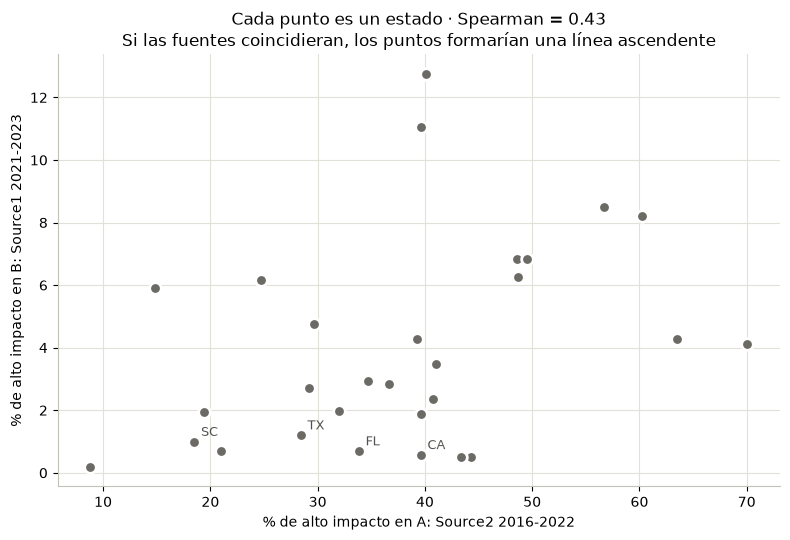

,Categoría,Variable,n A,% alto A,índice A,n B,% alto B,índice B,Lectura
3,CA,Estado,41099,39.59,1.17,46888,0.58,0.22,Contradictorio
41,TX,Estado,24865,28.41,0.84,10477,1.21,0.47,Sólido: menos alto impacto
8,FL,Estado,19254,33.82,1.00,31378,0.70,0.27,No concluyente
38,SC,Estado,16021,18.48,0.55,8484,1.00,0.39,Sólido: menos alto impacto
25,NC,Estado,12548,14.81,0.44,7539,5.90,2.28,Contradictorio
32,NY,Estado,10345,40.77,1.20,9488,2.35,0.91,No concluyente
36,PA,Estado,8089,24.70,0.73,9453,6.16,2.38,Contradictorio
12,IL,Estado,6997,36.67,1.08,1796,2.84,1.10,No concluyente
43,VA,Estado,6716,48.54,1.43,10896,6.83,2.64,Sólido: más alto impacto
9,GA,Estado,6633,60.26,1.78,3069,8.21,3.17,Sólido: más alto impacto


In [11]:
# Celda 3.4: % de alto impacto por estado en A frente a B (solo estados con muestra suficiente en ambos)
por_estado = comparar_grupos(silver, "State", "Estado")
comparables = por_estado[por_estado["Lectura"] != "Muestra insuficiente"]
rho_estados = comparables["% alto A"].corr(comparables["% alto B"], method="spearman")

print(f"Estados con al menos {MUESTRA_MINIMA} accidentes en ambos grupos: {len(comparables)}")
print(f"Correlación de Spearman entre el % de alto impacto de A y de B: {rho_estados:.2f}")
print(comparables["Lectura"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(comparables["% alto A"], comparables["% alto B"], s=70, color=COLOR_TODAS, edgecolor="white", linewidth=2)
for _, fila in comparables.nlargest(4, "n A").iterrows():       # se rotulan solo los 4 estados más grandes
    ax.annotate(fila["Categoría"], (fila["% alto A"], fila["% alto B"]), xytext=(5, 4),
                textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xlabel(f"% de alto impacto en {GRUPO_A}")
ax.set_ylabel(f"% de alto impacto en {GRUPO_B}")
ax.set_title(f"Cada punto es un estado · Spearman = {rho_estados:.2f}\nSi las fuentes coincidieran, los puntos formarían una línea ascendente")
plt.tight_layout()
guardar_figura(fig, "analisis_05_estados_A_vs_B")
plt.show()

comparables.sort_values("n A", ascending=False).head(10)

**Interpretación del lugar**

- Entre los **29 estados** con muestra suficiente en ambos grupos, la correlación de Spearman entre el % de alto impacto de A y de B es **0,43**: el orden de los estados **coincide poco** (1 sería el mismo orden).
- Algunos estados sí coinciden: **Georgia y Virginia** están sobre el promedio en ambos grupos; **Texas y Carolina del Sur**, por debajo.
- Pero el estado con más accidentes, **California, se contradice**: índice **1,17 en A** y **0,22 en B**. Lo mismo ocurre con Carolina del Norte y Pensilvania (7 estados contradictorios en total).

**Lectura prudente:** con estos datos **no se puede construir un ranking confiable de "estados con más colapsos"**; el resultado cambia según la fuente. La sub-pregunta 2 solo se responde en términos de **cantidad de casos dentro de cada fuente** (sección 2.2).

### 3.4 Sub-pregunta 3 — Clima: ¿con qué condiciones aumenta la proporción de alto impacto?

Solo se usan los registros con **clima confiable** (medido a máximo 1 h del accidente; dimensión de exactitud).

,Categoría,Variable,n A,% alto A,índice A,n B,% alto B,índice B,Lectura
0,Despejado,Clima,92904,31.39,0.93,95252,2.47,0.98,No concluyente
1,Lluvia,Clima,15881,39.68,1.18,12114,2.42,0.96,No concluyente
2,Niebla o humo,Clima,5714,28.88,0.86,5156,1.78,0.71,Sólido: menos alto impacto
3,Nieve o hielo,Clima,3982,44.02,1.31,6235,3.58,1.42,Sólido: más alto impacto
4,Nublado,Clima,103615,34.52,1.02,70419,2.59,1.03,No concluyente
5,Otro,Clima,51,47.06,1.40,150,2.67,1.06,Muestra insuficiente
6,Tormenta,Clima,2464,41.60,1.23,3020,2.02,0.80,Contradictorio
7,Muy reducida (<1 mi),Visibilidad,3173,31.58,0.94,3408,2.88,1.14,No concluyente
8,Normal (>=5 mi),Visibilidad,206388,33.49,0.99,175678,2.51,1.00,No concluyente
9,Reducida (1-5 mi),Visibilidad,15050,36.98,1.10,13050,2.56,1.01,No concluyente


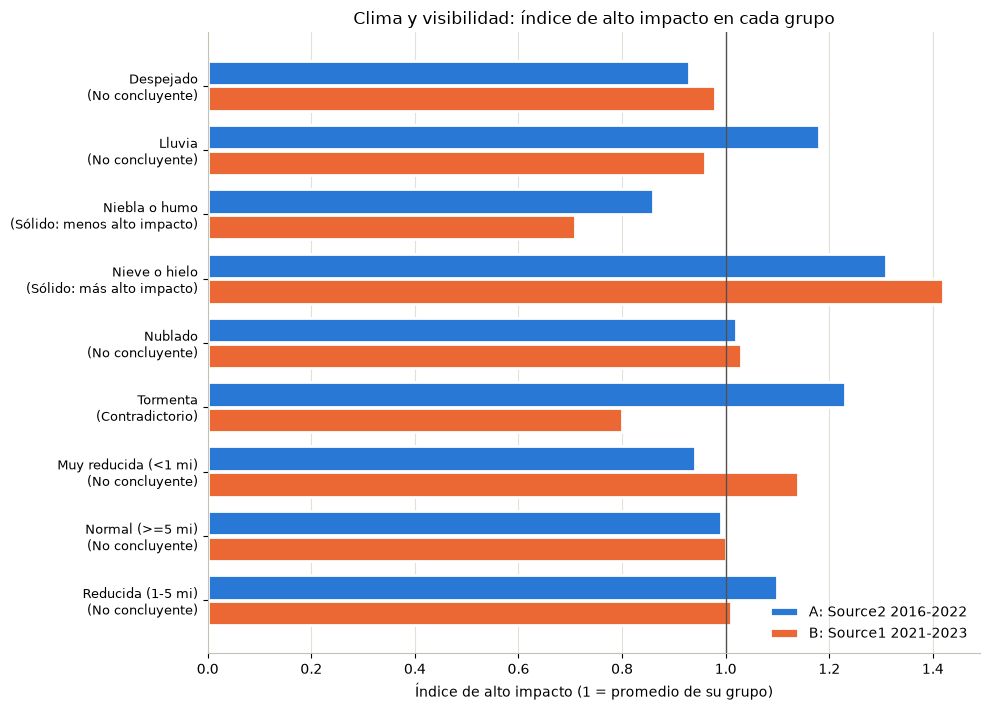

In [12]:
# Celda 3.5: clima agrupado y visibilidad
con_visibilidad = en_grupos[en_grupos["clima_confiable"] & en_grupos["visibilidad_grupo"].notna()]
clima = pd.concat([
    comparar_grupos(con_clima, "clima_grupo", "Clima"),
    comparar_grupos(con_visibilidad, "visibilidad_grupo", "Visibilidad"),
], ignore_index=True)
display(clima)
grafico_indices(clima, "Clima y visibilidad: índice de alto impacto en cada grupo", "analisis_06_indice_clima")

**Interpretación del clima**

- **Nieve o hielo** es el único clima **sólido con más alto impacto**: índice **1,31 en A y 1,42 en B**.
- **Niebla o humo** es **sólido con menos alto impacto** (0,86 y 0,71). Es contraintuitivo; una posible explicación (hipótesis, no comprobada) es que con niebla se conduce más despacio o hay menos tráfico.
- **Lluvia** sube en A (1,18) pero no en B (0,96): **no concluyente**. **Tormenta** es **contradictoria** (1,23 frente a 0,80).
- **Visibilidad:** ningún rango muestra un patrón común. Recordar que el sensor suele reportar como máximo 10 millas (notebook 01, sección 6.1), así que esta variable distingue poco.

### 3.5 Sub-pregunta 4 — Vía: ¿qué elementos cercanos acompañan al alto impacto?

Para cada elemento se compara el % de alto impacto de los accidentes **con** ese elemento cerca frente al promedio del grupo.

,Categoría,Variable,n A,% alto A,índice A,n B,% alto B,índice B,Lectura
0,Rampa o salida de autopista,Elemento de la vía,11717,57.61,1.70,13342,3.11,1.20,Sólido: más alto impacto
1,Semáforo,Elemento de la vía,51386,9.28,0.27,14873,3.10,1.20,Contradictorio
2,Cruce peatonal,Elemento de la vía,33489,7.41,0.22,17901,1.56,0.60,Sólido: menos alto impacto
3,Señal de pare,Elemento de la vía,7474,4.94,0.15,5264,2.89,1.12,Contradictorio


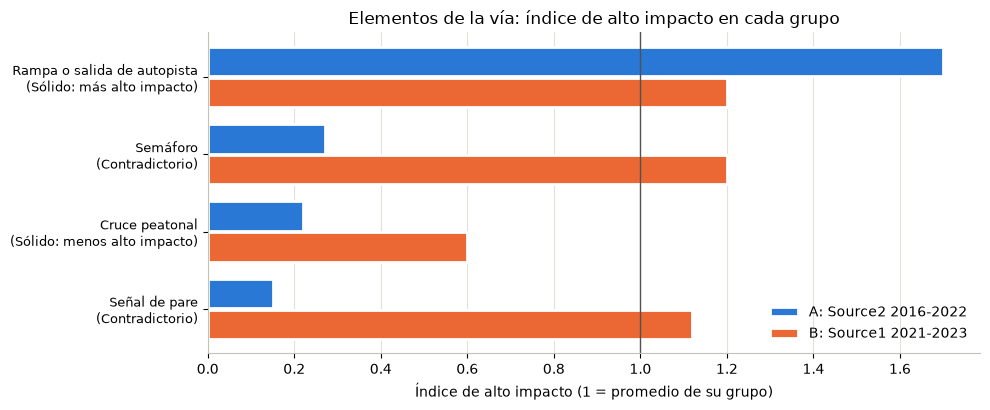

In [13]:
# Celda 3.6: elementos de la vía (filas = accidentes CON el elemento a poca distancia)
filas_via = []
for columna, nombre in ELEMENTOS_VIA.items():
    cerca = silver[columna].map({True: nombre, False: "Sin el elemento"})
    resumen = comparar_grupos(silver.assign(cerca=cerca), "cerca", "Elemento de la vía")
    filas_via.append(resumen[resumen["Categoría"] == nombre])
via = pd.concat(filas_via, ignore_index=True)
display(via)
grafico_indices(via, "Elementos de la vía: índice de alto impacto en cada grupo", "analisis_07_indice_via")

**Interpretación de la vía**

- **Rampas, salidas o entradas de autopista** (`Junction`): **sólido, más alto impacto** (índice **1,70 en A** y **1,20 en B**). Un accidente en una vía rápida tiende a afectar más el flujo.
- **Cruce peatonal:** **sólido, menos alto impacto** (0,22 y 0,60): son lugares de calle urbana, donde el tráfico ya va lento.
- **Semáforo y señal de pare** son **contradictorios**: en A tienen muy poco alto impacto (0,27 y 0,15) y en B un poco más que el promedio (1,20 y 1,12). Como vimos en 2.3, las fuentes cubren distintos tipos de calles, así que no se puede concluir nada sobre estos elementos.

### 3.6 Análisis multivariado: ¿los patrones se mantienen al combinar variables?

Un patrón puede ser engañoso si en realidad se debe a otra variable (por ejemplo, que los accidentes en rampas de autopista ocurran a otras horas). Por eso se combinan variables:
1. **Franja horaria × día de la semana** (mapa de calor del índice).
2. **Rampa de autopista × franja horaria**: ¿el mayor alto impacto en rampas aparece en todas las franjas?

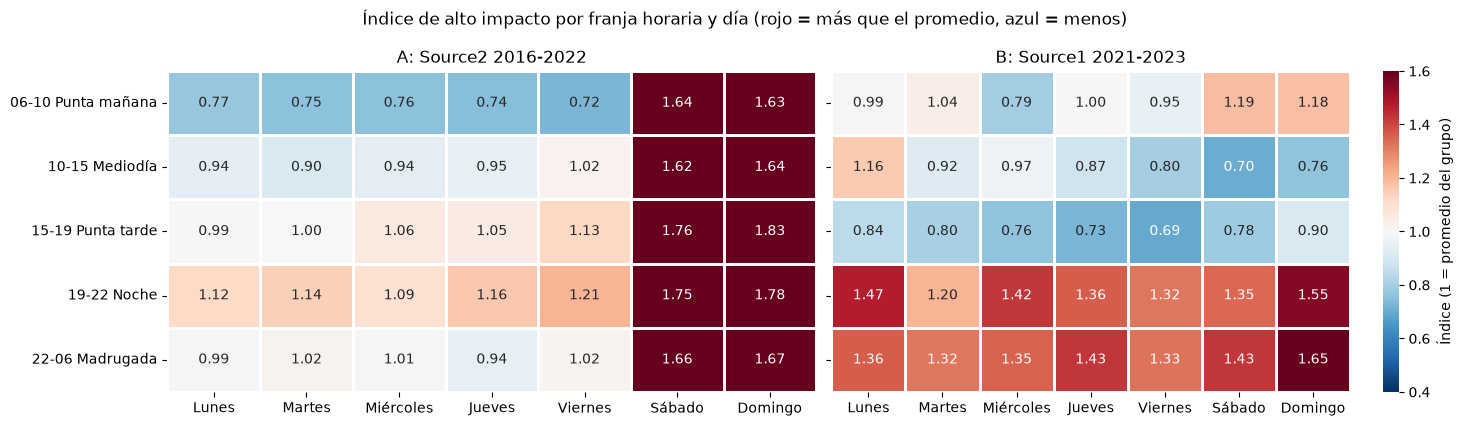

In [14]:
# Celda 3.7: mapa de calor franja × día de la semana (índice dentro de cada grupo)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for ax, grupo in zip(axes, GRUPOS):
    datos = silver[silver["grupo_severidad"] == grupo]
    tabla = datos.pivot_table(index="franja_horaria", columns="dia_semana", values="alto_impacto", aggfunc="mean")
    tabla = (tabla / datos["alto_impacto"].mean()).reindex(index=ORDEN_FRANJAS, columns=ORDEN_DIAS)
    sns.heatmap(tabla, ax=ax, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.4, vmax=1.6,
                linewidths=2, linecolor="white", cbar=(grupo == GRUPO_B),
                cbar_kws={"label": "Índice (1 = promedio del grupo)"})
    ax.set_title(grupo)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Índice de alto impacto por franja horaria y día (rojo = más que el promedio, azul = menos)")
plt.tight_layout()
guardar_figura(fig, "analisis_08_mapa_calor_franja_dia")
plt.show()

In [15]:
# Celda 3.8: ¿el patrón de las rampas de autopista se mantiene en cada franja horaria?
rampa_franja = (en_grupos.pivot_table(index="franja_horaria", columns=["grupo_severidad", "Junction"],
                                      values="alto_impacto", aggfunc="mean").mul(100).reindex(ORDEN_FRANJAS))
veces_mas = pd.DataFrame({
    f"{grupo}: con rampa / sin rampa": rampa_franja[(grupo, True)] / rampa_franja[(grupo, False)]
    for grupo in GRUPOS
}).round(2)
veces_mas

,A: Source2 2016-2022: con rampa / sin rampa,B: Source1 2021-2023: con rampa / sin rampa
franja_horaria,,
06-10 Punta mañana,2.01,1.06
10-15 Mediodía,1.77,1.07
15-19 Punta tarde,1.65,1.18
19-22 Noche,1.59,1.51
22-06 Madrugada,1.57,1.29


**Interpretación del análisis multivariado**

- **Mapa de calor:** en A el fin de semana está sobre el promedio en **todas** las franjas (1,62 a 1,83), mientras que en B el fin de semana casi no se distingue. Lo que **sí se repite en los dos mapas** es la **noche (19–22 h)**: está sobre el promedio en **los 7 días de ambos grupos** (de 1,09 a 1,78). Esto refuerza el hallazgo de la sección 3.2.
- **Rampas por franja:** en A, un accidente cerca de una rampa tiene entre **1,57 y 2,01 veces** más proporción de alto impacto que uno lejos de ella, en las 5 franjas. En B la razón es mayor que 1 en todas las franjas (1,06 a 1,51), aunque de día es pequeña. Por lo tanto, el patrón de las rampas **no se explica solo por la hora** del accidente.

### 3.7 Matriz de solidez: resumen del diagnóstico

Se juntan todos los patrones evaluados. **Solo los "sólidos" se usarán para recomendar**; los demás quedan como preguntas abiertas.

In [16]:
# Celda 3.9: matriz de solidez (todas las comparaciones en una tabla)
matriz = pd.concat([tiempo, clima, via], ignore_index=True)
matriz = matriz[matriz["Lectura"] != "Muestra insuficiente"]

with pd.option_context("display.max_rows", 60):
    display(matriz[["Variable", "Categoría", "índice A", "índice B", "Lectura"]])
print(matriz["Lectura"].value_counts().to_string())

,Variable,Categoría,índice A,índice B,Lectura
0,Franja horaria,06-10 Punta mañana,0.80,0.98,No concluyente
1,Franja horaria,10-15 Mediodía,1.06,0.88,No concluyente
2,Franja horaria,15-19 Punta tarde,1.12,0.77,Contradictorio
3,Franja horaria,19-22 Noche,1.23,1.38,Sólido: más alto impacto
4,Franja horaria,22-06 Madrugada,1.08,1.41,No concluyente
5,Tipo de día,Fin de semana,1.69,1.08,No concluyente
6,Tipo de día,Laborable,0.92,0.98,No concluyente
7,Luz (Day/Night),Day,0.98,0.85,No concluyente
8,Luz (Day/Night),Night,1.06,1.30,No concluyente
9,Clima,Despejado,0.93,0.98,No concluyente


Lectura
No concluyente                13
Contradictorio                 4
Sólido: más alto impacto       3
Sólido: menos alto impacto     2


**Interpretación de la matriz:** de **22 patrones** evaluados, solo **5 son sólidos** (23 %):

| Más alto impacto en ambos grupos | Menos alto impacto en ambos grupos |
|---|---|
| Noche 19–22 h · Nieve o hielo · Rampa o salida de autopista | Niebla o humo · Cruce peatonal |

Hay **4 contradictorios** (punta de la tarde, tormenta, semáforo, señal de pare) y **13 no concluyentes**. Esto confirma por qué no se deben dar por ciertos los resultados de una sola fuente: **la mayoría de los patrones que parecen claros en un grupo no se repiten en el otro**.

---
## 4. Análisis prescriptivo (nivel 4): ¿qué conviene hacer?

Para decidir dónde poner recursos hay que distinguir dos cosas que **no son lo mismo**:

- **Cantidad:** ¿en qué franja ocurren **más** accidentes de alto impacto? → sirve para **dimensionar** equipos (cuántas grúas o patrullas).
- **Proporción:** ¿en qué franja un accidente tiene **más probabilidad** de ser de alto impacto? → sirve para **priorizar la respuesta** (protocolos de despeje rápido).

Como las franjas no duran lo mismo (la madrugada dura 8 horas y la noche solo 3), la cantidad se divide entre las horas de cada franja.

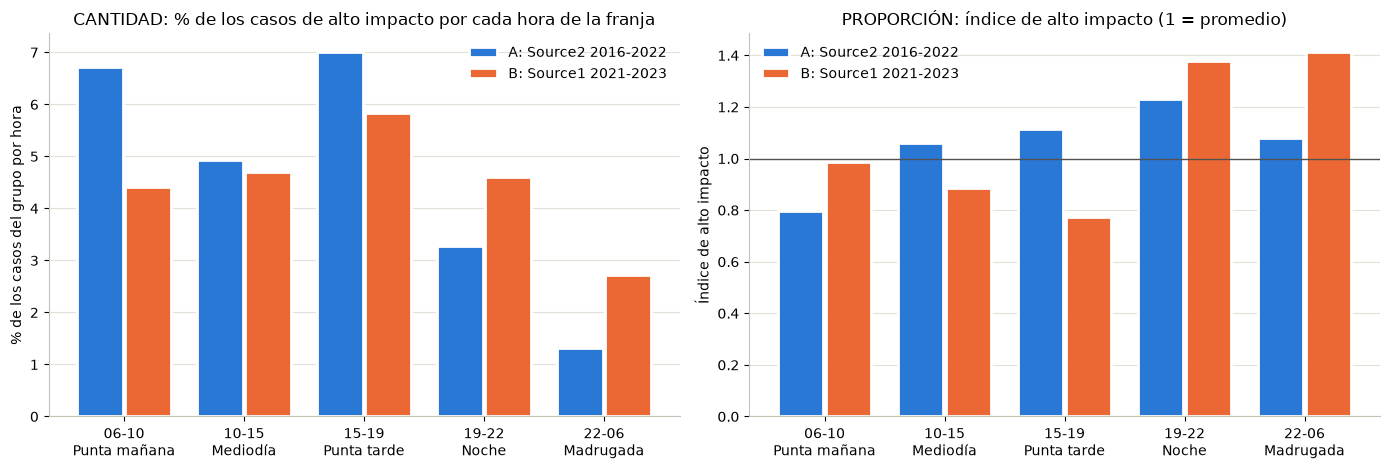

% de casos por hora de franja                                    indice                     
grupo_severidad             A: Source2 2016-2022 B: Source1 2021-2023 A: Source2 2016-2022 B: Source1 2021-2023
franja_horaria                                                                                                 
06-10 Punta mañana                          6.72                 4.42                 0.80                 0.98
10-15 Mediodía                              4.94                 4.69                 1.06                 0.88
15-19 Punta tarde                           7.02                 5.84                 1.12                 0.77
19-22 Noche                                 3.29                 4.60                 1.23                 1.38
22-06 Madrugada                             1.31                 2.72                 1.08                 1.41

In [17]:
# Celda 4.1: cantidad (casos por hora de franja) frente a proporción (índice) en cada franja
franjas = tasa_por_categoria(silver, "franja_horaria")
franjas["% de los casos de alto impacto"] = (franjas["alto_impacto"]
                                             / franjas.groupby("grupo_severidad")["alto_impacto"].transform("sum") * 100)
franjas["% de casos por hora de franja"] = franjas["% de los casos de alto impacto"] / franjas["franja_horaria"].map(HORAS_FRANJA)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(ORDEN_FRANJAS))
for desplazamiento, grupo in [(-0.2, GRUPO_A), (0.2, GRUPO_B)]:
    d = franjas[franjas["grupo_severidad"] == grupo].set_index("franja_horaria").reindex(ORDEN_FRANJAS)
    axes[0].bar(x + desplazamiento, d["% de casos por hora de franja"], width=0.38, color=COLORES[grupo],
                label=grupo, edgecolor="white", linewidth=2)
    axes[1].bar(x + desplazamiento, d["indice"], width=0.38, color=COLORES[grupo],
                label=grupo, edgecolor="white", linewidth=2)
axes[0].set_title("CANTIDAD: % de los casos de alto impacto por cada hora de la franja")
axes[0].set_ylabel("% de los casos del grupo por hora")
axes[1].set_title("PROPORCIÓN: índice de alto impacto (1 = promedio)")
axes[1].set_ylabel("Índice de alto impacto")
axes[1].axhline(1, color="#52514e", linewidth=1)
for ax, posicion in zip(axes, ["upper right", "upper left"]):
    ax.set_xticks(x, [f.replace(" ", "\n", 1) for f in ORDEN_FRANJAS])
    ax.legend(frameon=False, loc=posicion)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
guardar_figura(fig, "analisis_09_cantidad_vs_proporcion")
plt.show()

(franjas.pivot(index="franja_horaria", columns="grupo_severidad",
               values=["% de casos por hora de franja", "indice"]).reindex(ORDEN_FRANJAS).round(2))

**Interpretación: cantidad no es lo mismo que proporción**

- **Cantidad:** la **punta de la tarde (15–19 h)** concentra la mayor cantidad de casos de alto impacto por hora en **ambos** grupos (**7,0 %** por hora en A y **5,8 %** en B). La madrugada tiene la menor cantidad por hora en ambos.
- **Proporción:** en A la probabilidad más alta está en la **noche (19–22 h, índice 1,23)**; en B, en la madrugada (1,41) y la noche (1,38). La noche es la **única franja alta en ambos grupos**, y la punta de la tarde, con más casos, tiene en B una proporción baja (0,77).
- Las dos lecturas llevan a **decisiones distintas**: más equipos donde hay **más casos** (tarde) y protocolos de respuesta rápida donde un accidente tiene **más probabilidad** de colapsar el tráfico (noche).

In [18]:
# Celda 4.2: recomendaciones, cada una con su evidencia, su solidez y lo que falta validar
def evidencia(categoria):
    fila = matriz[matriz["Categoría"] == categoria].iloc[0]
    return f"índice A = {fila['índice A']:.2f} · B = {fila['índice B']:.2f} ({fila['Lectura']})"


cant = franjas.pivot(index="franja_horaria", columns="grupo_severidad", values="% de casos por hora de franja")
recomendaciones = pd.DataFrame([
    ("Dimensionar grúas, patrullas y ambulancias con más turnos en la punta de la tarde (15–19 h)",
     f"Franja con más casos de alto impacto por hora en ambos grupos: A = {cant.loc['15-19 Punta tarde', GRUPO_A]:.1f} %/h · "
     f"B = {cant.loc['15-19 Punta tarde', GRUPO_B]:.1f} %/h",
     "Alta", "Contrastar con los registros propios del departamento de transporte de cada estado", "Departamento de transporte"),
    ("Mantener protocolos de despeje rápido en la noche (19–22 h), aunque haya menos accidentes",
     "19-22 Noche: " + evidencia("19-22 Noche"),
     "Media", "Medir el tiempo real de respuesta nocturno; el dataset no tiene volumen de tráfico", "Policía de tránsito / emergencias"),
    ("Priorizar el despeje rápido de accidentes en rampas, salidas y entradas de autopista",
     "Rampa: " + evidencia("Rampa o salida de autopista") + "; se mantiene en las 5 franjas (celda 3.8)",
     "Media", "Confirmar con un registro de tipo de vía más preciso que la cercanía en OpenStreetMap", "Departamento de transporte"),
    ("Activar protocolos especiales cuando hay nieve o hielo",
     "Nieve o hielo: " + evidencia("Nieve o hielo"),
     "Media", "Pocos casos (≈ 2–3 % de los accidentes); revisar por estado con datos locales de clima", "Departamento de transporte"),
    ("No asignar recursos por estado según el % de alto impacto mientras la severidad no tenga un criterio común",
     f"El ranking de estados de A y B casi no coincide (Spearman = {rho_estados:.2f})",
     "Alta (es una regla de calidad)", "Usar conteos dentro de una misma fuente, nunca porcentajes que mezclen fuentes", "Equipo de análisis"),
    ("Documentar y unificar el criterio de severidad de cada fuente y año",
     "Source1 pasó de ~33 % a < 3 % de alto impacto y dejó de usar el nivel 3 (notebook 02, sección 6)",
     "Alta (gobierno de datos)", "Pedir al mantenedor la definición de severidad por fuente", "Mantenedor del dataset / proveedores"),
    ("No tomar decisiones sobre lluvia, tormenta, semáforos o señales de pare con estos datos",
     "Lluvia: " + evidencia("Lluvia") + " · Semáforo: " + evidencia("Semáforo"),
     "—", "Requiere datos de volumen de tráfico y de lluvia más completos (precipitación tenía 28,58 % de nulos)", "Equipo de análisis"),
], columns=["Recomendación (propuesta, no certeza)", "Evidencia", "Solidez", "Qué falta validar antes de aplicarla", "Responsable sugerido"])

with pd.option_context("display.max_colwidth", None):
    display(recomendaciones)

,"Recomendación (propuesta, no certeza)",Evidencia,Solidez,Qué falta validar antes de aplicarla,Responsable sugerido
0,"Dimensionar grúas, patrullas y ambulancias con más turnos en la punta de la tarde (15–19 h)",Franja con más casos de alto impacto por hora en ambos grupos: A = 7.0 %/h · B = 5.8 %/h,Alta,Contrastar con los registros propios del departamento de transporte de cada estado,Departamento de transporte
1,"Mantener protocolos de despeje rápido en la noche (19–22 h), aunque haya menos accidentes",19-22 Noche: índice A = 1.23 · B = 1.38 (Sólido: más alto impacto),Media,Medir el tiempo real de respuesta nocturno; el dataset no tiene volumen de tráfico,Policía de tránsito / emergencias
2,"Priorizar el despeje rápido de accidentes en rampas, salidas y entradas de autopista",Rampa: índice A = 1.70 · B = 1.20 (Sólido: más alto impacto); se mantiene en las 5 franjas (celda 3.8),Media,Confirmar con un registro de tipo de vía más preciso que la cercanía en OpenStreetMap,Departamento de transporte
3,Activar protocolos especiales cuando hay nieve o hielo,Nieve o hielo: índice A = 1.31 · B = 1.42 (Sólido: más alto impacto),Media,Pocos casos (≈ 2–3 % de los accidentes); revisar por estado con datos locales de clima,Departamento de transporte
4,No asignar recursos por estado según el % de alto impacto mientras la severidad no tenga un criterio común,El ranking de estados de A y B casi no coincide (Spearman = 0.43),Alta (es una regla de calidad),"Usar conteos dentro de una misma fuente, nunca porcentajes que mezclen fuentes",Equipo de análisis
5,Documentar y unificar el criterio de severidad de cada fuente y año,"Source1 pasó de ~33 % a < 3 % de alto impacto y dejó de usar el nivel 3 (notebook 02, sección 6)",Alta (gobierno de datos),Pedir al mantenedor la definición de severidad por fuente,Mantenedor del dataset / proveedores
6,"No tomar decisiones sobre lluvia, tormenta, semáforos o señales de pare con estos datos",Lluvia: índice A = 1.18 · B = 0.96 (No concluyente) · Semáforo: índice A = 0.27 · B = 1.20 (Contradictorio),—,"Requiere datos de volumen de tráfico y de lluvia más completos (precipitación tenía 28,58 % de nulos)",Equipo de análisis


**Cómo leer las recomendaciones:** son **propuestas** para el usuario principal (departamentos de transporte), no conclusiones definitivas.

- **Solidez alta:** el resultado aparece en ambos grupos y no depende de la severidad (cantidad de casos), o es una regla de calidad de datos.
- **Solidez media:** el patrón es sólido en ambos grupos, pero tiene limitaciones conocidas (pocos casos, ubicación aproximada, sin volumen de tráfico).
- Las recomendaciones de **no actuar** son tan importantes como las de actuar: evitan asignar recursos sobre evidencia contradictoria.

---
## 5. Capa Gold: productos listos para consumo

Gold guarda **resultados agregados y reproducibles**, no copias del detalle. Cualquier informe o tablero posterior debe partir de estas tablas para usar exactamente las mismas cifras.

In [19]:
# Celda 5.1: exportar las tablas del análisis a data/gold/us_accidents/
artefactos = {
    "gold_alto_impacto_por_hora.csv": por_hora,
    "gold_cantidad_vs_proporcion_franja.csv": franjas,
    "gold_alto_impacto_por_estado.csv": por_estado,
    "gold_matriz_solidez.csv": matriz,
    "gold_recomendaciones.csv": recomendaciones,
}
for nombre, tabla in artefactos.items():
    tabla.to_csv(GOLD_DIR / nombre, index=False, encoding="utf-8-sig")

print("Gold:")
for nombre in artefactos:
    print(f"  {(GOLD_DIR / nombre).relative_to(PROJECT_ROOT)}")
print("Gráficos:")
for p in sorted(OUTPUT_DIR.glob("analisis_*.png")):
    print(f"  {p.relative_to(PROJECT_ROOT)}")

Gold:
  data\gold\us_accidents\gold_alto_impacto_por_hora.csv
  data\gold\us_accidents\gold_cantidad_vs_proporcion_franja.csv
  data\gold\us_accidents\gold_alto_impacto_por_estado.csv
  data\gold\us_accidents\gold_matriz_solidez.csv
  data\gold\us_accidents\gold_recomendaciones.csv
Gráficos:
  outputs\us_accidents\analisis_01_accidentes_por_hora.png
  outputs\us_accidents\analisis_02_top_estados_alto_impacto.png
  outputs\us_accidents\analisis_03_trampa_mezclar_fuentes.png
  outputs\us_accidents\analisis_04_indice_por_hora.png
  outputs\us_accidents\analisis_05_estados_A_vs_B.png
  outputs\us_accidents\analisis_06_indice_clima.png
  outputs\us_accidents\analisis_07_indice_via.png
  outputs\us_accidents\analisis_08_mapa_calor_franja_dia.png
  outputs\us_accidents\analisis_09_cantidad_vs_proporcion.png


---
## 6. Conclusiones

Cada conclusión sigue la plantilla vista en clase: **hallazgo** (qué se observó), **evidencia** (qué cálculo lo sustenta), **interpretación** (qué sugiere, sin afirmar causas) y **limitación** (qué no se puede afirmar).

### Conclusión 1 — La severidad registrada no es comparable entre fuentes ni entre años
- **Hallazgo:** al mezclar fuentes, el alto impacto parece caer de **35,8 % (2017) a 6,8 % (2022)**; dentro de cada grupo comparable casi no cambia (A: 30–37 %; B: 2,5–2,6 %).
- **Evidencia:** celda 3.1 y notebook 02 (sección 6): Source1 pasó de ~33 % a menos de 3 % de alto impacto y dejó de usar el nivel 3 desde 2021, mientras su peso en los datos subió de 23,8 % a 86,4 %.
- **Interpretación:** la "caída" es un efecto de **cambio en la forma de registrar**, no una mejora del tráfico. Toda comparación de severidad debe hacerse dentro de un grupo.
- **Limitación:** no existe documentación pública del criterio de severidad de cada fuente; la explicación es una **hipótesis** que solo el mantenedor puede confirmar.

### Conclusión 2 — Cuándo: de noche el alto impacto es más probable, pero en la tarde hay más casos
- **Hallazgo:** la franja **19–22 h** tiene más proporción de alto impacto en ambos grupos (índice **1,23 y 1,38**), y por hora el patrón se mantiene de **20 h a 3 h**. La mayor **cantidad** de casos ocurre en la **punta de la tarde (15–19 h)**: 7,0 % y 5,8 % de los casos por hora.
- **Evidencia:** celdas 3.2, 3.3, 3.7 (la noche supera el promedio los 7 días en ambos grupos) y 4.1.
- **Interpretación:** de noche hay menos accidentes, pero cuando ocurren es más probable que colapsen el tráfico. Posibles explicaciones —mayor velocidad, menos personal de respuesta, menor visibilidad— son **hipótesis** que este dataset no permite probar.
- **Limitación:** no hay volumen de tráfico ni tiempos de respuesta. Además, según el paper, de 23 h a 6 h las fuentes se consultaban cada 150 s en lugar de cada 90 s, lo que podría dejar fuera algunos accidentes nocturnos. El efecto del fin de semana solo es claro en A.

### Conclusión 3 — Vía: las rampas de autopista acompañan al alto impacto; los cruces peatonales, no
- **Hallazgo:** cerca de rampas o salidas de autopista el índice es **1,70 (A) y 1,20 (B)**, y el patrón se mantiene en las 5 franjas; cerca de cruces peatonales es **0,22 y 0,60**. Semáforo y señal de pare se **contradicen** entre grupos.
- **Evidencia:** celdas 3.6 y 3.8.
- **Interpretación:** el **tipo de vía** se asocia con el impacto: un accidente en una vía rápida tiende a alterar más el flujo que uno en una calle urbana.
- **Limitación:** los elementos de la vía no se observan en el lugar: se asignan si el mapa de OpenStreetMap (2019) tiene uno a menos de 30 m o 100 m. Además, las fuentes cubren distintos tipos de calles (22 % de A cerca de semáforos frente a 7 % de B). Es una asociación, no una causa.

### Conclusión 4 — Clima: la nieve o el hielo acompañan al alto impacto; la lluvia no muestra un patrón común
- **Hallazgo:** con nieve o hielo el índice es **1,31 (A) y 1,42 (B)**; con niebla o humo, **0,86 y 0,71**. Lluvia, tormenta y visibilidad no son concluyentes o se contradicen.
- **Evidencia:** celda 3.5 (solo registros con clima medido a máximo 1 h del accidente).
- **Interpretación:** las condiciones de nieve o hielo podrían dificultar el despeje de la vía, pero la lluvia —el clima adverso más frecuente— no tiene un efecto común en ambas fuentes.
- **Limitación:** el clima viene de la estación de aeropuerto más cercana, no del punto del accidente; nieve o hielo es solo el 1,8–3,2 % de los accidentes; la precipitación se excluyó por tener 28,58 % de nulos.

### Conclusión 5 — Dónde: no se puede afirmar qué estados tienen más colapsos
- **Hallazgo:** los casos se concentran en pocos estados (top 3: 38,1 % en A y 34,3 % en B), pero no son los mismos estados, y el % de alto impacto por estado coincide poco entre fuentes (Spearman **0,43**; California: 1,17 en A y 0,22 en B).
- **Evidencia:** celdas 2.2 y 3.4.
- **Interpretación:** el "dónde" depende más de **la cobertura de cada fuente** que de diferencias reales comprobables entre estados.
- **Limitación:** no se tiene la población ni los kilómetros de vías de cada estado para normalizar los conteos.

---
### Respuesta a la pregunta motivadora

> **¿Cuándo, dónde y bajo qué condiciones un accidente se convierte en un colapso del tráfico?**

Con la evidencia disponible, y **sin afirmar causas**, la respuesta es **parcial**:

| Sub-pregunta | Respuesta | Solidez |
|---|---|---|
| 1. ¿Cuándo? | Es **más probable de noche (19–22 h, y por hora de 20 h a 3 h)**; la **mayor cantidad** de casos está en la **punta de la tarde (15–19 h)** | Sólida en ambas fuentes |
| 2. ¿Dónde? | No se puede responder por proporción: los estados cambian según la fuente. Solo se puede decir dónde hay **más casos dentro de cada fuente** | Débil |
| 3. ¿Bajo qué clima? | Con **nieve o hielo** (más) y con niebla (menos). La lluvia y la tormenta no son concluyentes | Sólida solo para nieve/hielo y niebla |
| 4. ¿Qué vía? | Cerca de **rampas o salidas de autopista** (más) y de cruces peatonales (menos). Semáforo y pare se contradicen | Sólida solo para rampas y cruces |

**Utilidad para la decisión:** los datos permiten **priorizar hipótesis y franjas** para el control vial (tarde para dimensionar equipos, noche y autopistas para respuesta rápida), pero **no** asignar recursos por estado ni decidir sin validar con información local del departamento de transporte.

---
### Limitaciones generales del análisis

1. **Muestra del 7 %** (semilla fija): los porcentajes deberían ser parecidos en el dataset completo, pero los conteos absolutos no.
2. **Solo accidentes reportados** por las APIs de tráfico; no son todos los accidentes ocurridos.
3. **Severidad = impacto en el tráfico**, con criterios distintos por fuente y por año y sin documentación pública. Por eso solo se compara dentro de grupos, y el 19,85 % de Silver no entra en las comparaciones de severidad.
4. **Sin volumen de tráfico (exposición):** no se sabe cuántos vehículos circulaban; un mayor % de alto impacto no significa necesariamente un mayor riesgo por vehículo.
5. **Oportunidad:** los datos terminan en marzo de 2023 (Source2 en septiembre de 2022). Los patrones podrían haber cambiado.
6. **Exactitud aproximada:** el clima viene de estaciones de aeropuerto y los elementos de la vía de un mapa de 2019 por cercanía.
7. **Reglas prácticas, no pruebas estadísticas:** el mínimo de 500 accidentes y el umbral de 10 % son criterios simples y explicables; otro umbral podría cambiar algunas lecturas "no concluyentes".